In [61]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from sklearn import linear_model
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, mean_absolute_error
from math import sqrt
import seaborn as sns
import numpy as np

#Choose whether to save plots
save_plots = True

#Choose whether to threshold by number of sensors
toggle_threshold = True 

#threshold min number of stations required per pixel
sensor_threshold = 2

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)


def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out

def savefig(name):
    fig_path = "/home/nlring/Documents/01_Research/larc-chicago-haq/figures/"
    if toggle_threshold == False:
        fig_name = fig_path + "/no-threshold/" + name
    else:
        fig_name = fig_path + name
    if save_plots == True:
        return plt.savefig(fig_name)


#define the paths for the hourly and time-of-day datasets.
hourly_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-hourly.csv"
diurnal_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-diurnal.csv"
nowinter_dat_path  = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-diurnal-nowinter.csv"

fulldat_path = "~/Documents/01_Research/larc-chicago-haq/datasets/clarity-tempo-full.csv"

#load full data
# ct_hourly_full = xr.open_dataset(hourly_dat_path)
# ct_diurnal_full = xr.open_dataset(diurnal_dat_path)
# ct_nowinter_full = xr.open_dataset(nowinter_dat_path)

ct_hourly_full = pd.read_csv(hourly_dat_path)
ct_diurnal_full = pd.read_csv(diurnal_dat_path)
ct_nowinter_full = pd.read_csv(nowinter_dat_path)
ct_fulldat = pd.read_csv(fulldat_path)

ct_fulldat = ct_fulldat.rename({"no2ConcIndividual.value":"sfc_no2"})


#subset and filter pixel by sensor count.
if toggle_threshold == True:
    # ct_hourly = ct_hourly_full.where(ct_hourly_full.sensor_count >= sensor_threshold)
    # ct_diurnal = ct_diurnal_full.where(ct_diurnal_full.sensor_count >= sensor_threshold)
    # ct_nowinter = ct_nowinter_full.where(ct_nowinter_full.sensor_count >= sensor_threshold)

    ct_hourly = ct_hourly_full.loc[ct_hourly_full['sensor_count'] >= sensor_threshold]
    ct_diurnal = ct_diurnal_full.loc[ct_diurnal_full['sensor_count'] >= sensor_threshold]
    ct_nowinter = ct_nowinter_full.loc[ct_nowinter_full['sensor_count'] >= sensor_threshold]
    ct_full_dat = ct_fulldat.loc[ct_fulldat['sensor_count'] >= sensor_threshold]
else:
    ct_hourly = ct_hourly_full
    ct_diurnal = ct_diurnal_full
    ct_nowinter = ct_nowinter_full
    ct_full_dat = ct_fulldat


#load full data
print(ct_hourly)
print(ct_diurnal)

         Unnamed: 0             datetime  latitude  longitude  sfc_no2_mean  \
2                 2  2025-09-04 11:00:00     41.67     -87.63     11.300000   
3                 3  2025-09-04 11:00:00     41.67     -87.61     12.715000   
5                 5  2025-09-04 11:00:00     41.67     -87.55     13.940000   
6                 6  2025-09-04 11:00:00     41.67     -87.53     10.400000   
8                 8  2025-09-04 11:00:00     41.69     -87.63     14.960000   
...             ...                  ...       ...        ...           ...   
1085694     1085694  2026-06-01 23:00:00     41.99     -87.75     11.007647   
1085700     1085700  2026-06-01 23:00:00     42.01     -87.81      8.883125   
1085703     1085703  2026-06-01 23:00:00     42.01     -87.71      7.682353   
1085704     1085704  2026-06-01 23:00:00     42.01     -87.69      7.790000   
1085705     1085705  2026-06-01 23:00:00     42.01     -87.67      9.122941   

         sfc_no2_median  sfc_no2_var  sfc_no2_sd  s

## Basic Linear Model
Here we apply a basic linear model to all data for the study period.

Coef:  3.733632903492429e-16
Rank:  1.0
Intercept:  11.472971107892945
0.07406099823634682
                datetime  latitude  longitude  sfc_no2_mean  col_no2_mean  \
138  2025-09-04 12:00:00     41.67     -87.63     12.774000  4.954445e+15   
139  2025-09-04 12:00:00     41.67     -87.61     11.578333  4.620537e+15   
141  2025-09-04 12:00:00     41.67     -87.55     12.705000  4.801101e+15   
142  2025-09-04 12:00:00     41.67     -87.53     11.377143  4.788616e+15   
146  2025-09-04 12:00:00     41.69     -87.63     13.190000  5.096934e+15   

     no2_estimate  
138     13.322779  
139     13.198110  
141     13.265526  
142     13.260865  
146     13.375979  


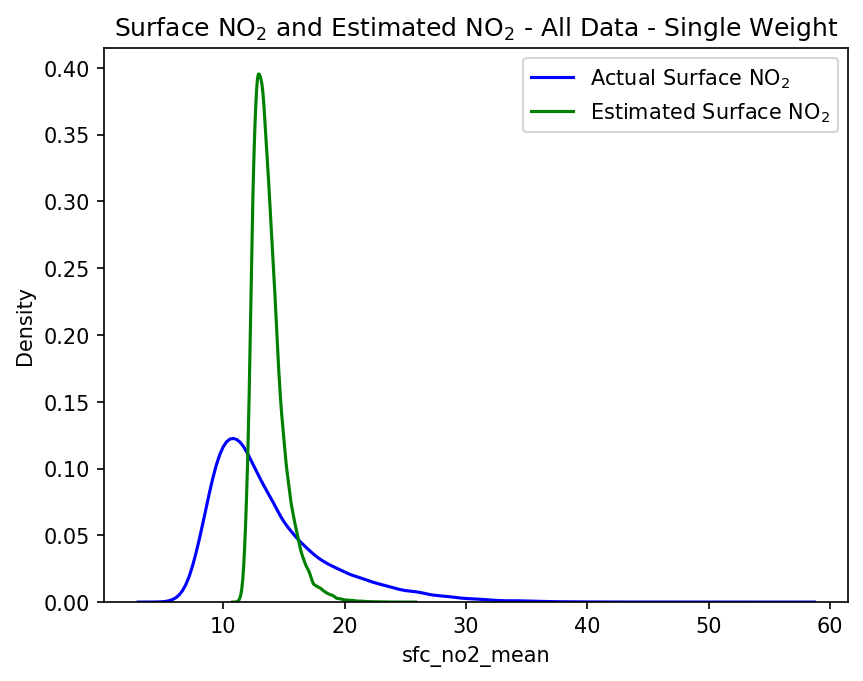

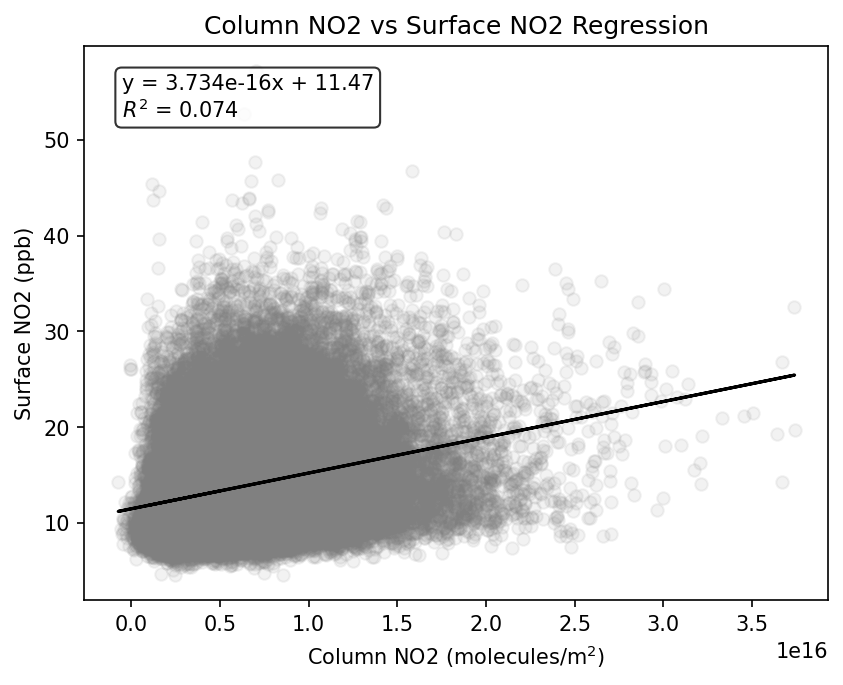

In [62]:
# tempo_vals =  ct_hourly.column_no2_mean.to_dataframe().reset_index()
# clarity_vals = ct_hourly.sfc_no2_mean.to_dataframe().reset_index()

vals = ct_hourly[['datetime','latitude','longitude','sfc_no2_mean','col_no2_mean']].dropna()


x = vals['col_no2_mean'].to_frame()
y = vals['sfc_no2_mean'].to_frame()

model = linear_model.LinearRegression().fit(X=x, y=y)
score = model.score(X=x, y=y)

coef = float(np.ravel(model.coef_)[0])
rank = float(np.ravel(model.rank_)[0])
intercept = float(np.ravel(model.intercept_)[0])

print("Coef: ", coef)
print("Rank: ", rank)
print("Intercept: ", intercept)

print(score)

vals['no2_estimate'] = vals['col_no2_mean'].apply(lambda x: x*float(coef)+float(intercept))
print(vals.head())

sns.kdeplot(vals, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(vals, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

eqn_text = f"y = {coef:.3e}x + {intercept:.2f}\n$R^2$ = {score:.3f}"

plt.scatter(x, y, color='grey', alpha=0.1)
plt.plot(x, model.predict(x),color='k' )
plt.title("Column NO2 vs Surface NO2 Regression")
plt.xlabel("Column NO2 (molecules/m$^2$)")
plt.ylabel("Surface NO2 (ppb)")
plt.annotate(eqn_text, xy=(0.05, 0.95), xycoords='axes fraction',
             ha='left', va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

savefig("column-no2-vs-sfc-no2-alldata.png")
plt.show()




## Linear Regression - Time of Day - Single Weight


Coef:  1.1986509030488649e-15
Rank:  1.0
Intercept:  7.3149410596644655
0.20309209121983074
      hour  latitude  longitude  sfc_no2_mean  col_no2_mean  no2_estimate
1865    11     41.67     -87.63     16.051250  5.267957e+15     13.629382
1866    11     41.67     -87.61     15.730146  5.336276e+15     13.711273
1869    11     41.67     -87.55     15.542864  5.604059e+15     14.032251
1870    11     41.67     -87.53     14.274444  5.840753e+15     14.315965
1874    11     41.69     -87.63     15.309510  5.618571e+15     14.049647


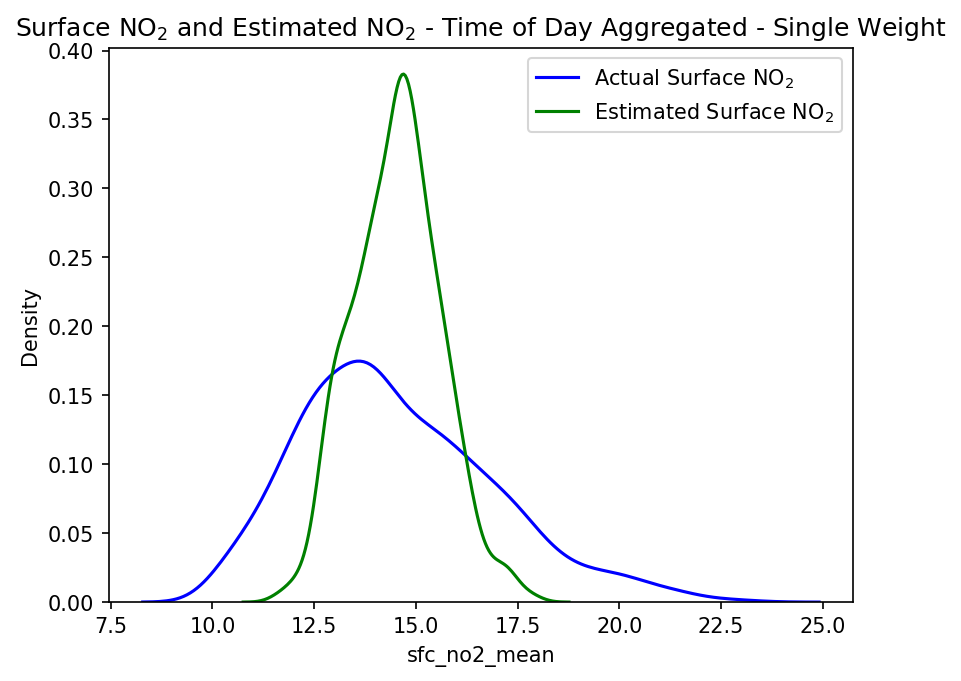

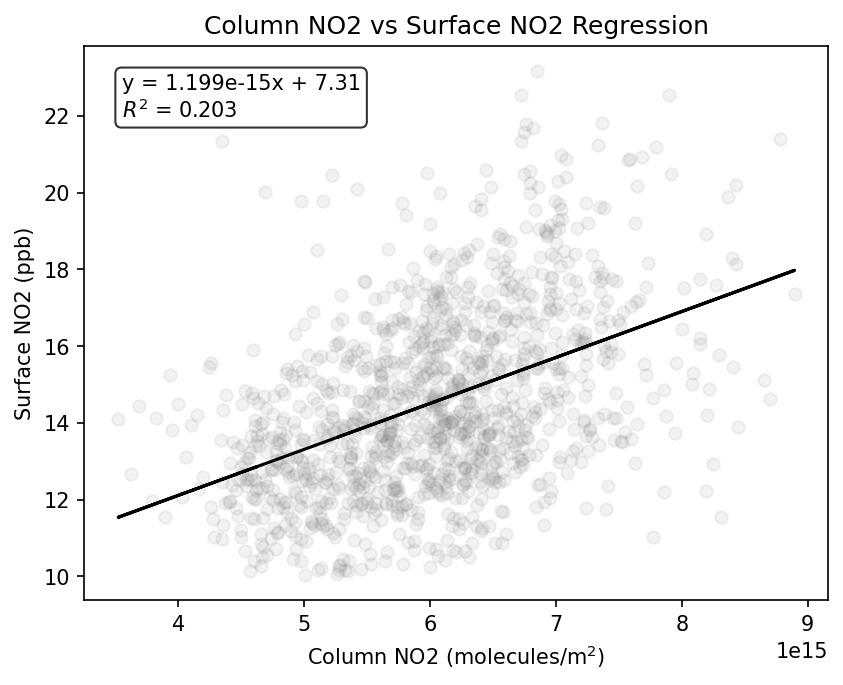

In [63]:
both = ct_diurnal[['hour','latitude','longitude','sfc_no2_mean','col_no2_mean']].dropna()

x = both['col_no2_mean'].to_frame()
y = both['sfc_no2_mean'].to_frame()

model = linear_model.LinearRegression().fit(X=x, y=y)
score = model.score(X=x, y=y)

coef = float(np.ravel(model.coef_)[0])
rank = float(np.ravel(model.rank_)[0])
intercept = float(np.ravel(model.intercept_)[0])

print("Coef: ", coef)
print("Rank: ", rank)
print("Intercept: ", intercept)

print(score)

both['no2_estimate'] = both['col_no2_mean'].apply(lambda x: x*float(coef)+float(intercept))
print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Time of Day Aggregated - Single Weight")
plt.legend()
savefig("kde-actual-and-estimated-tod-single-weight.png")
plt.show()


eqn_text = f"y = {coef:.3e}x + {intercept:.2f}\n$R^2$ = {score:.3f}"

plt.scatter(x, y, color='grey', alpha=0.1)
plt.plot(x, model.predict(x),color='k' )
plt.title("Column NO2 vs Surface NO2 Regression")
plt.xlabel("Column NO2 (molecules/m$^2$)")
plt.ylabel("Surface NO2 (ppb)")
plt.annotate(eqn_text, xy=(0.05, 0.95), xycoords='axes fraction',
             ha='left', va='top', fontsize=10,
             bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
savefig("column-no2-vs-sfc-no2-regression-tod-single-weight.png")
plt.show()


## Linear Regression - Time of Day - Hourly Weights

    hour          coef  intercept     score
0     11  8.860760e-16  11.372095  0.200866
1     12  1.695370e-15   6.803782  0.282137
2     13  1.468387e-15   7.197205  0.246474
3     14  1.232224e-15   7.420756  0.179992
4     15  1.191026e-15   6.176762  0.196448
5     16  8.750462e-16   7.681913  0.107420
6     17  6.988464e-16   8.740482  0.075259
7     18  1.051809e-15   6.707220  0.116658
8     19  1.250221e-15   5.842879  0.122793
9     20  1.356249e-15   5.805860  0.207681
10    21  1.054898e-15   7.772878  0.173991
11    22  1.368192e-15   6.643222  0.230945
12    23  1.281839e-15   8.501736  0.240125
   hour  latitude  longitude  sfc_no2_mean  col_no2_mean          coef  \
0    11     41.67     -87.63     16.051250  5.267957e+15  8.860760e-16   
1    11     41.67     -87.61     15.730146  5.336276e+15  8.860760e-16   
2    11     41.67     -87.55     15.542864  5.604059e+15  8.860760e-16   
3    11     41.67     -87.53     14.274444  5.840753e+15  8.860760e-16   
4    11     41

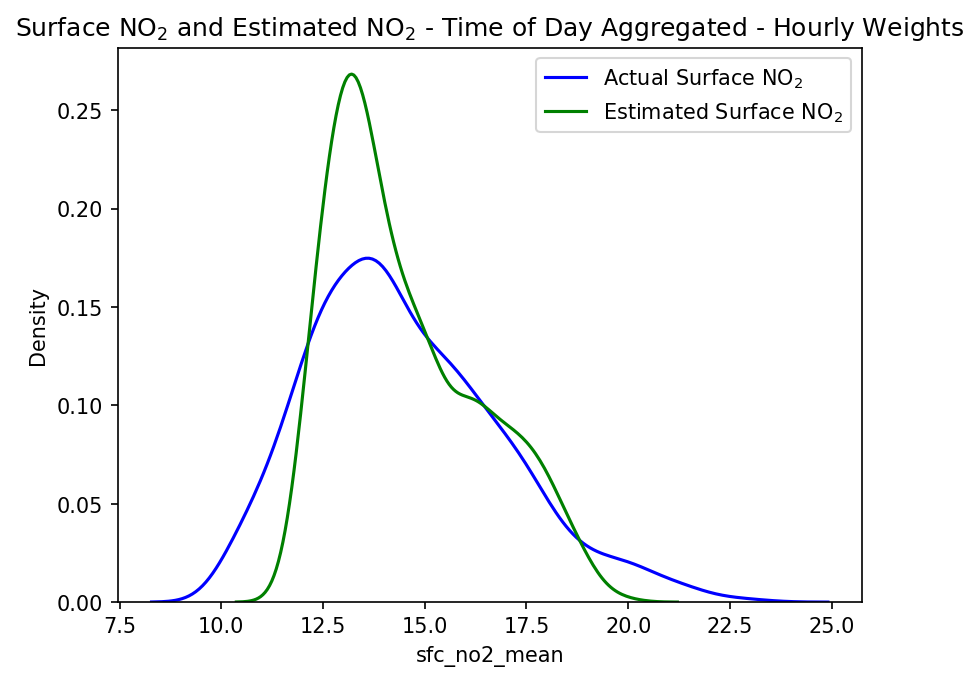

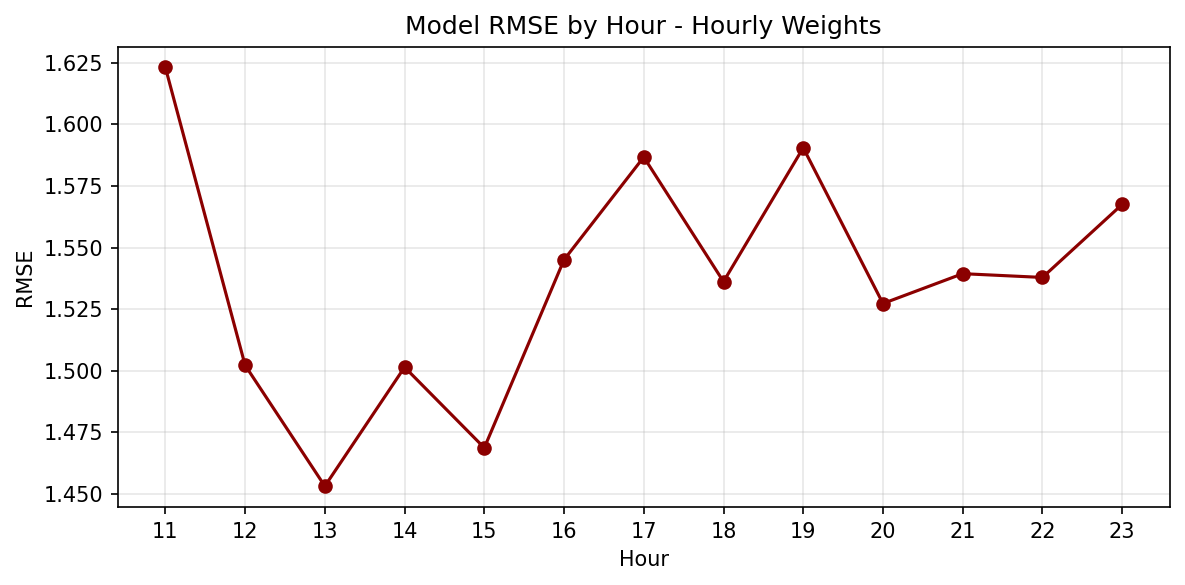

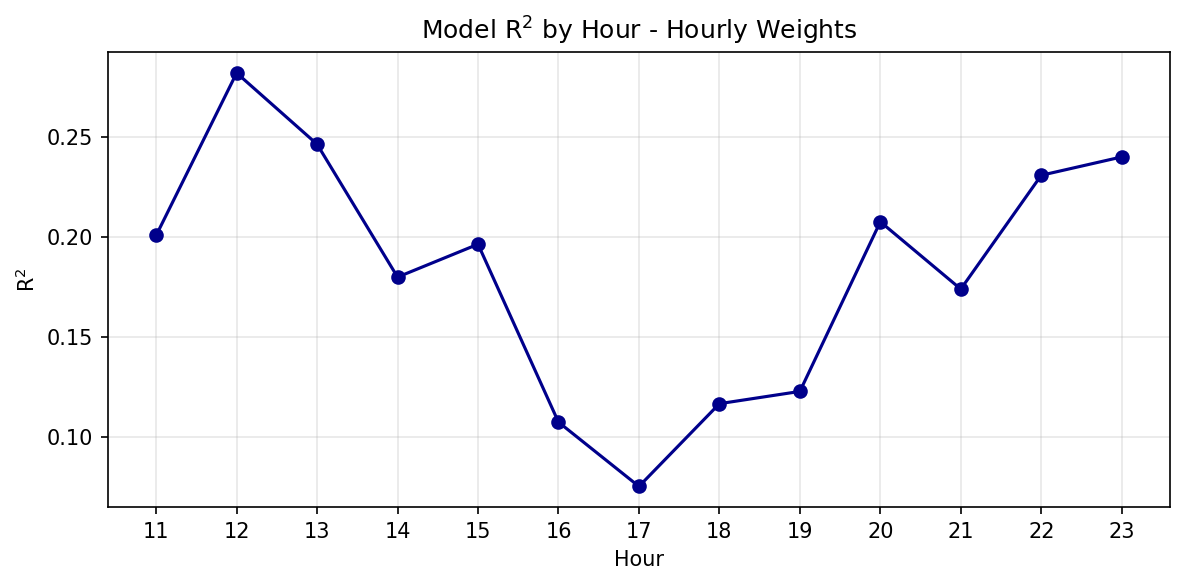

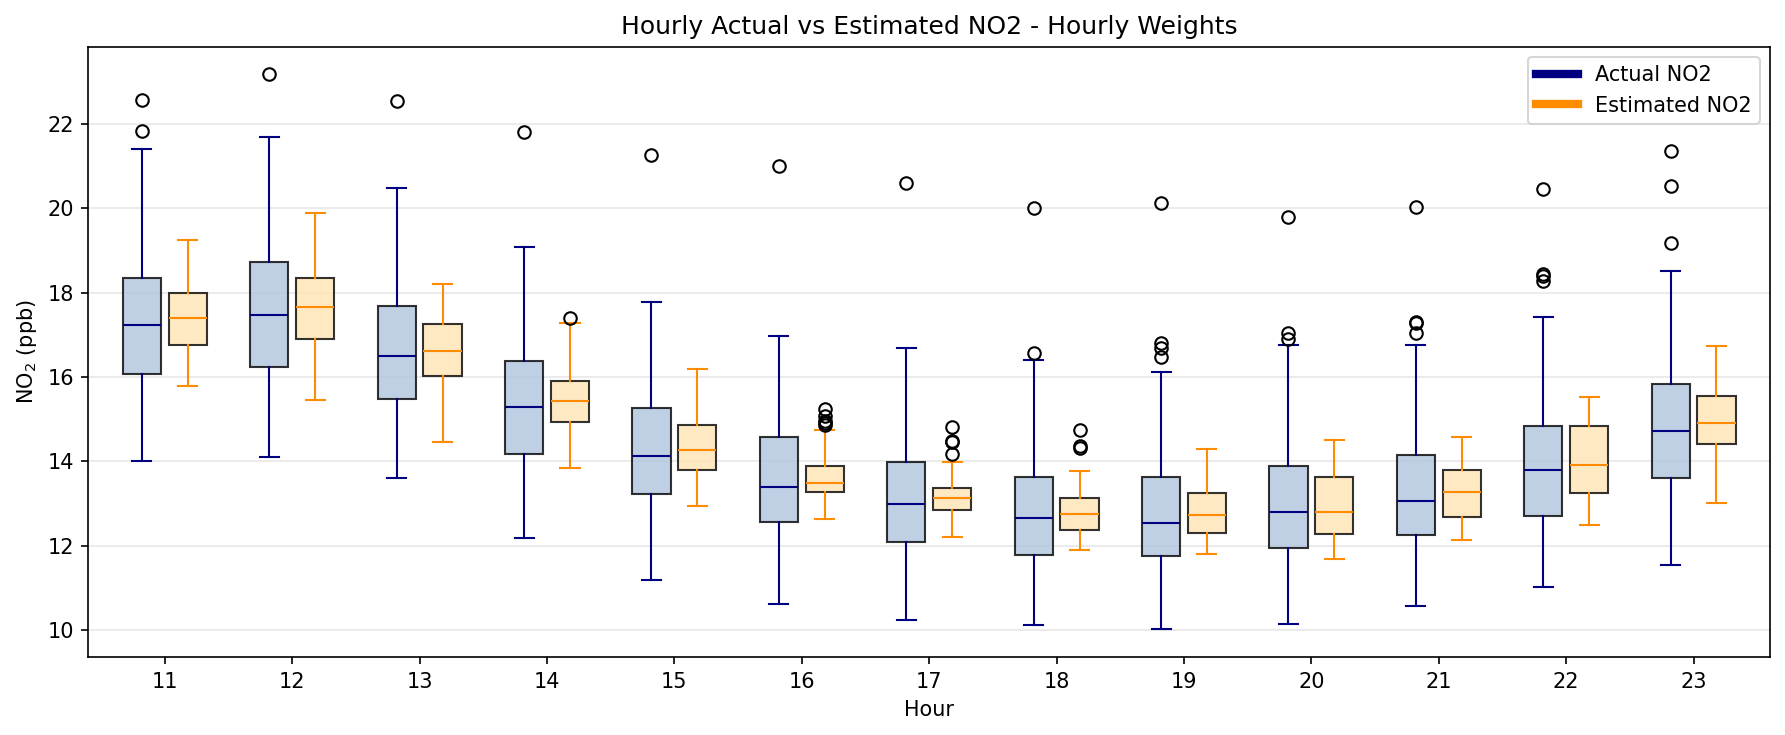

In [64]:
# tempo_vals =  ct_diurnal.column_no2_mean.to_dataframe().reset_index()
# clarity_vals = ct_diurnal.sfc_no2_mean.to_dataframe().reset_index()

# both = clarity_vals.merge(tempo_vals, on=['latitude', 'longitude', 'hour']).dropna()

both = ct_diurnal[['hour','latitude','longitude','sfc_no2_mean','col_no2_mean']].dropna()

model_rows = []
for hour in sorted(both['hour'].dropna().unique()):
    x_hour = both.loc[both['hour'] == hour, ['col_no2_mean']]
    y_hour = both.loc[both['hour'] == hour, ['sfc_no2_mean']]

    if len(x_hour) < 2:
        continue

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'coef': float(hour_model.coef_.ravel()[0]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })

model_vals = pd.DataFrame(model_rows)
print(model_vals)

both = both.merge(model_vals, on='hour', how='left')
both['no2_estimate'] = both['col_no2_mean'] * both['coef'] + both['intercept']

hour_rmse = both.groupby('hour').apply(
    lambda group: rmse(group['sfc_no2_mean'], group['no2_estimate'])
)
both['rmse'] = both['hour'].map(hour_rmse)

print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Time of Day Aggregated - Hourly Weights")
plt.legend()
savefig("kde-actual-and-estimated-tod-hourly-weight.png")
plt.show()

hour_rmse_df = hour_rmse.reset_index()
hour_rmse_df.columns = ['hour', 'rmse']

plt.figure(figsize=(8, 4))
plt.plot(hour_rmse_df['hour'], hour_rmse_df['rmse'], marker='o', color='darkred')
plt.xticks(hour_rmse_df['hour'])
plt.xlabel('Hour')
plt.ylabel('RMSE')
plt.title('Model RMSE by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-rmse.png")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(model_vals['hour'], model_vals['score'], marker='o', color='darkblue')
plt.xticks(model_vals['hour'])
plt.xlabel('Hour')
plt.ylabel('R$^2$')
plt.title('Model R$^2$ by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-r2.png")
plt.show()


hour_dat = both[['hour']].drop_duplicates().sort_values('hour').reset_index(drop=True)

hours = [int(hour) for hour in hour_dat['hour'].to_list()]
actual_by_hour = [both.loc[both['hour'] == hour, 'sfc_no2_mean'].dropna() for hour in hours]
estimated_by_hour = [both.loc[both['hour'] == hour, 'no2_estimate'].dropna() for hour in hours]

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [hour - 0.18 for hour in hours]
positions_estimated = [hour + 0.18 for hour in hours]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(hours)
ax.set_xticklabels(hours)
ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
ax.set_xlabel('Hour')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Hourly Actual vs Estimated NO2 - Hourly Weights')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()

savefig("boxplots-actual-vs-estimated-no2-hourly-weights.png")
plt.show()

## Linear Regression - Time of Day - Hourly Weights - Month Filtering

This section is run over data with months Dec 2025, Jan 2026, and Feb 2026 filtered out due to the significant number of missing values over the dataset. These data are merged and filtered using the clarity-tempo-aggregation.ipynb notebook.

    hour          coef  intercept     score
0     11  9.354734e-16  10.888205  0.215067
1     12  1.725339e-15   6.350354  0.288096
2     13  1.499820e-15   6.510478  0.237449
3     14  1.210399e-15   6.477222  0.197588
4     15  1.146452e-15   5.518093  0.207632
5     16  7.245947e-16   7.911959  0.097929
6     17  6.383950e-16   8.358688  0.088419
7     18  1.015769e-15   6.396611  0.154509
8     19  1.097839e-15   6.192816  0.160355
9     20  1.000009e-15   7.094751  0.190457
10    21  9.920906e-16   7.436383  0.178396
11    22  1.333896e-15   5.988627  0.219630
12    23  1.259384e-15   7.736907  0.231452
   hour  latitude  longitude  sfc_no2_mean  col_no2_mean          coef  \
0    11     41.67     -87.63     15.994763  5.267957e+15  9.354734e-16   
1    11     41.67     -87.61     15.672491  5.336276e+15  9.354734e-16   
2    11     41.67     -87.55     15.524521  5.604059e+15  9.354734e-16   
3    11     41.67     -87.53     14.242059  5.840753e+15  9.354734e-16   
4    11     41

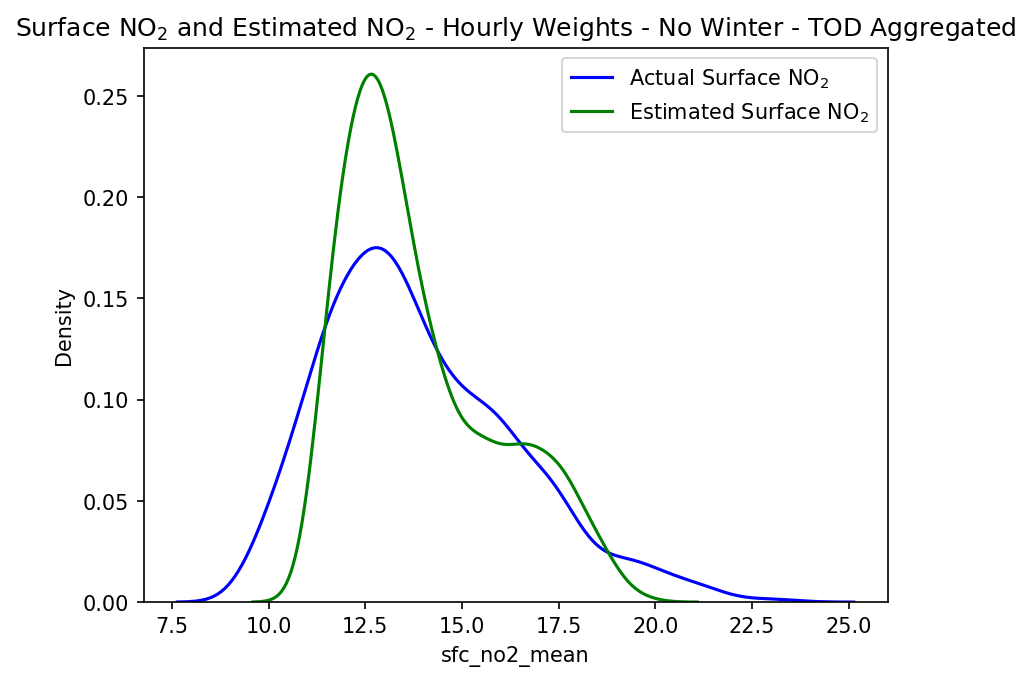

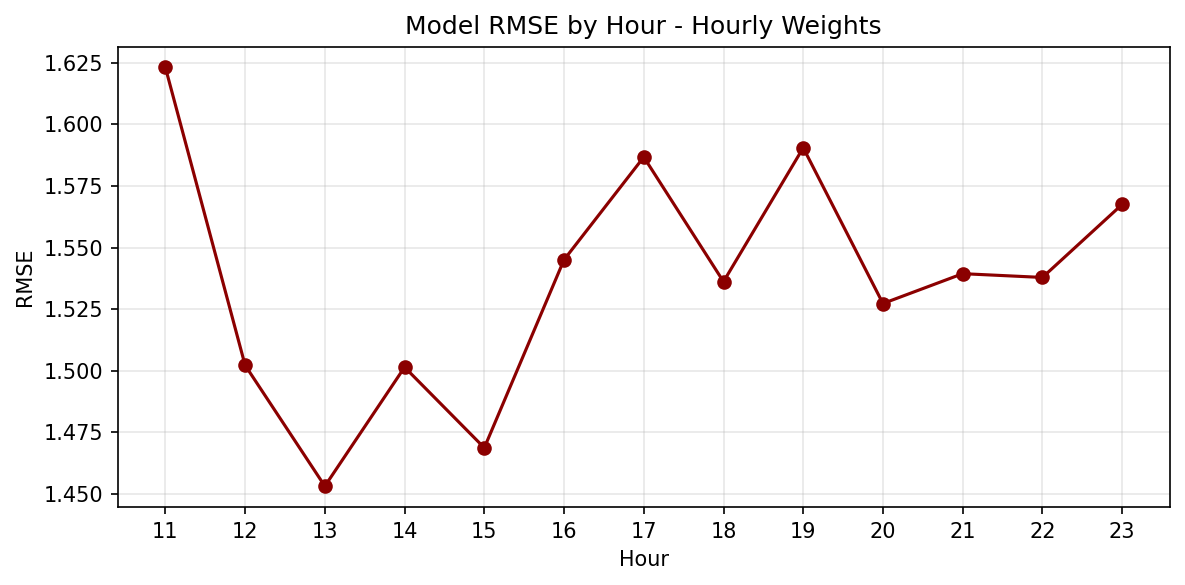

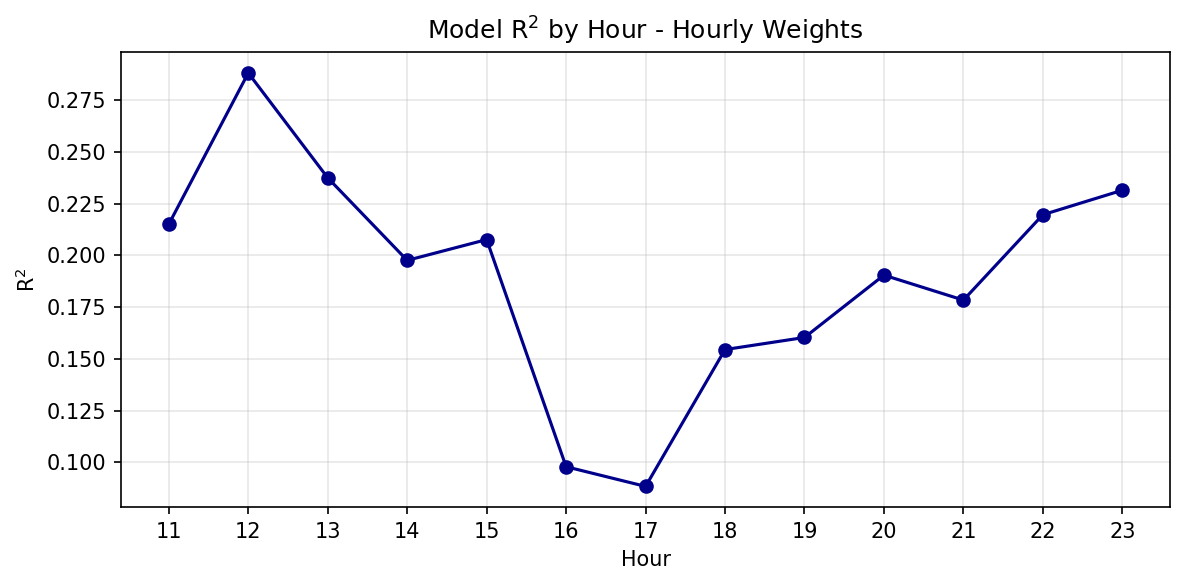

In [65]:


# clarity_vals = ct_nowinter.sfc_no2_mean.to_dataframe().reset_index()
# tempo_vals =  ct_nowinter.column_no2_mean.to_dataframe().reset_index()

# both = clarity_vals.merge(tempo_vals, on=['latitude', 'longitude', 'hour']).dropna()


both = ct_nowinter[['hour','latitude','longitude','sfc_no2_mean','col_no2_mean']].dropna()

model_rows = []
for hour in sorted(both['hour'].dropna().unique()):
    x_hour = both.loc[both['hour'] == hour, ['col_no2_mean']]
    y_hour = both.loc[both['hour'] == hour, ['sfc_no2_mean']]

    if len(x_hour) < 2:
        continue

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'coef': float(hour_model.coef_.ravel()[0]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })

model_vals = pd.DataFrame(model_rows)
print(model_vals)

both = both.merge(model_vals, on='hour', how='left')
both['no2_estimate'] = both['col_no2_mean'] * both['coef'] + both['intercept']

hour_rmse = both.groupby('hour').apply(
    lambda group: rmse(group['sfc_no2_mean'], group['no2_estimate'])
)

# spatial_rmse = both.groupby('hour').apply(
#     lambda group: rmse(group['sfc_no2_mean'], group['no2_estimate'])
# )

both['rmse'] = both['hour'].map(hour_rmse)

print(both.head())

sns.kdeplot(both, x="sfc_no2_mean", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Hourly Weights - No Winter - TOD Aggregated")
plt.legend()
savefig("kde-actual-and-estimated-tod-hourly-weights-nowinter.png")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(hour_rmse_df['hour'], hour_rmse_df['rmse'], marker='o', color='darkred')
plt.xticks(hour_rmse_df['hour'])
plt.xlabel('Hour')
plt.ylabel('RMSE')
plt.title('Model RMSE by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-nowinter-rmse.png")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(model_vals['hour'], model_vals['score'], marker='o', color='darkblue')
plt.xticks(model_vals['hour'])
plt.xlabel('Hour')
plt.ylabel('R$^2$')
plt.title('Model R$^2$ by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-nowinter-r2.png")
plt.show()

# ALLDATA LIN REG

In [66]:
ct_full_dat

,Unnamed: 0,year,month,doy,hour,datetime_x,latitude,longitude,no2ConcIndividual.value,column_no2,datetime_y,sensor_count
1071,1071,2025,9,247,11,2025-09-04 11:54:46,41.67,-87.63,11.30,NaN,2025-09-04 11:47:23.030562560,4.0
1072,1072,2025,9,247,11,2025-09-04 11:54:10,41.67,-87.61,14.17,NaN,2025-09-04 11:47:23.030562560,2.0
1073,1073,2025,9,247,11,2025-09-04 11:59:18,41.67,-87.61,11.26,NaN,2025-09-04 11:47:23.030562560,2.0
1076,1076,2025,9,247,11,2025-09-04 11:57:01,41.67,-87.55,15.02,NaN,2025-09-04 11:47:23.030562560,2.0
1077,1077,2025,9,247,11,2025-09-04 11:53:39,41.67,-87.55,12.86,NaN,2025-09-04 11:47:23.030562560,2.0
...,...,...,...,...,...,...,...,...,...,...,...,...
17110856,17110856,2026,6,152,23,2026-06-01 23:16:48,42.01,-87.67,8.59,9.730209e+14,2026-06-01 23:46:54.031260416,2.0
17110857,17110857,2026,6,152,23,2026-06-01 23:02:36,42.01,-87.67,9.69,NaN,2026-06-01 23:06:46.024763648,2.0
17110858,17110858,2026,6,152,23,2026-06-01 23:02:36,42.01,-87.67,9.69,9.730209e+14,2026-06-01 23:46:54.031260416,2.0
17110859,17110859,2026,6,152,23,2026-06-01 23:08:21,42.01,-87.67,10.62,NaN,2026-06-01 23:06:46.024763648,2.0


    hour          coef  intercept     score
0     11  1.192614e-15  11.645195  0.264029
1     12  1.225015e-15  10.690851  0.243111
2     13  8.520273e-16  11.615405  0.135817
3     14  5.046590e-16  12.216290  0.085285
4     15  3.665113e-16  11.572252  0.085751
5     16  2.820996e-16  11.438605  0.054203
6     17  2.641113e-16  11.185934  0.041917
7     18  3.107011e-16  10.712590  0.049421
8     19  2.390022e-16  11.035732  0.027886
9     20  1.744231e-16  11.049417  0.016290
10    21  1.710445e-16  11.077517  0.013703
11    22  9.913656e-17  11.462465  0.004798
12    23  2.238097e-16  11.653408  0.023054
   hour  latitude  longitude  no2ConcIndividual.value    column_no2  \
0    12     41.67     -87.63                    16.02  4.954445e+15   
1    12     41.67     -87.63                    11.40  4.954445e+15   
2    12     41.67     -87.63                    15.70  4.954445e+15   
3    12     41.67     -87.63                    15.75  4.954445e+15   
4    12     41.67     -87.63 

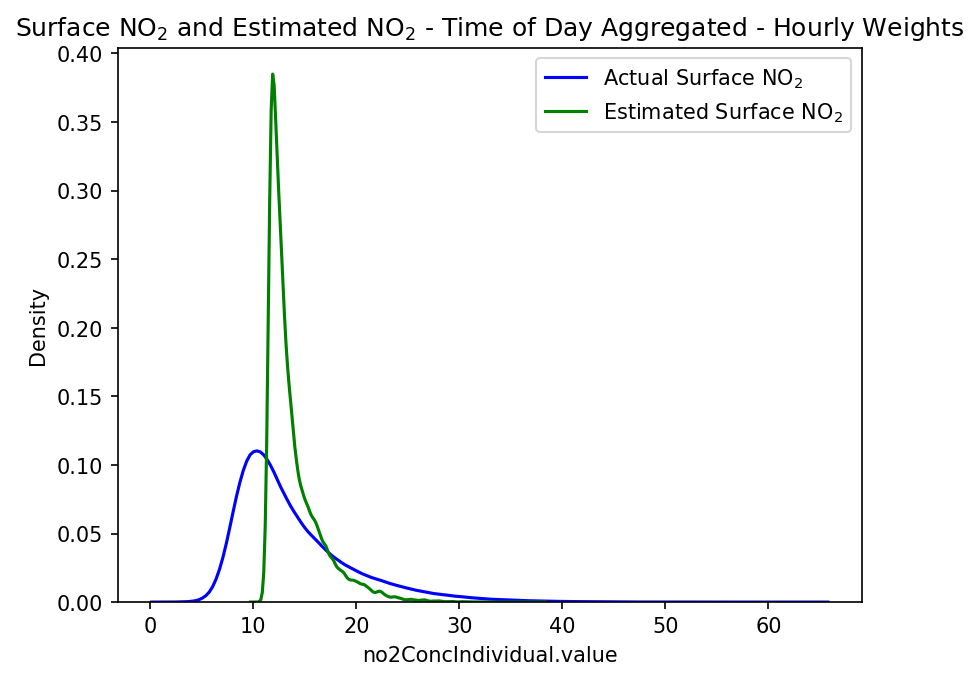

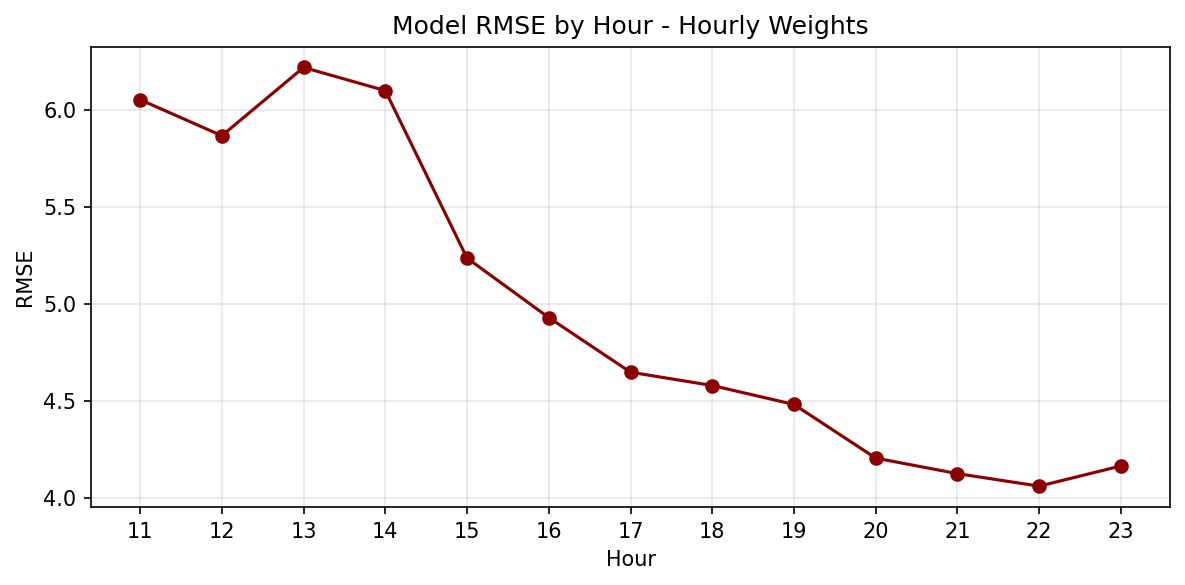

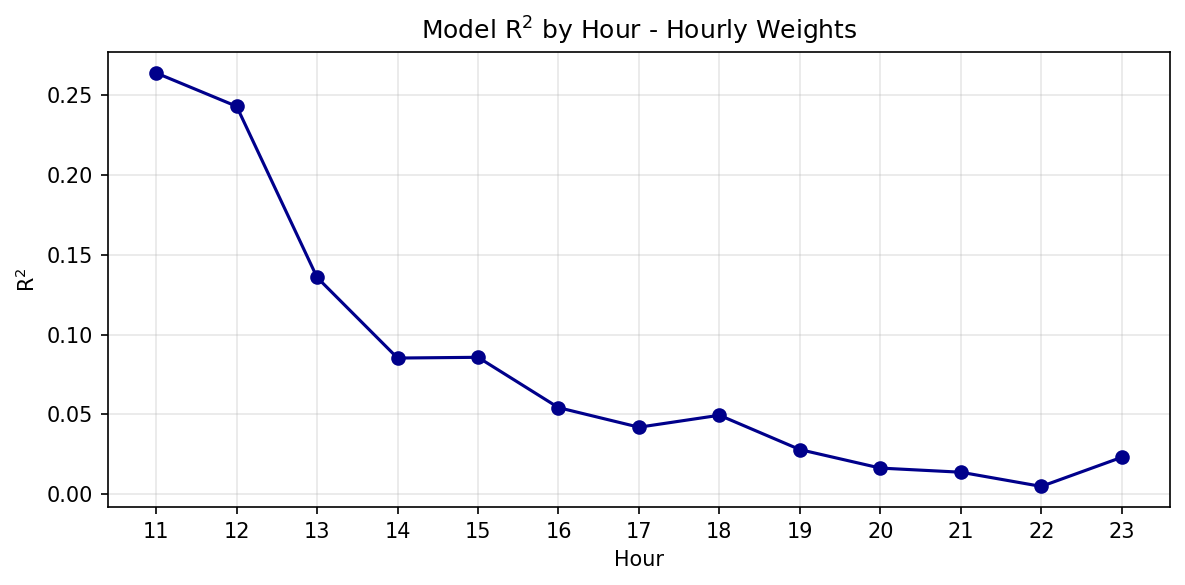

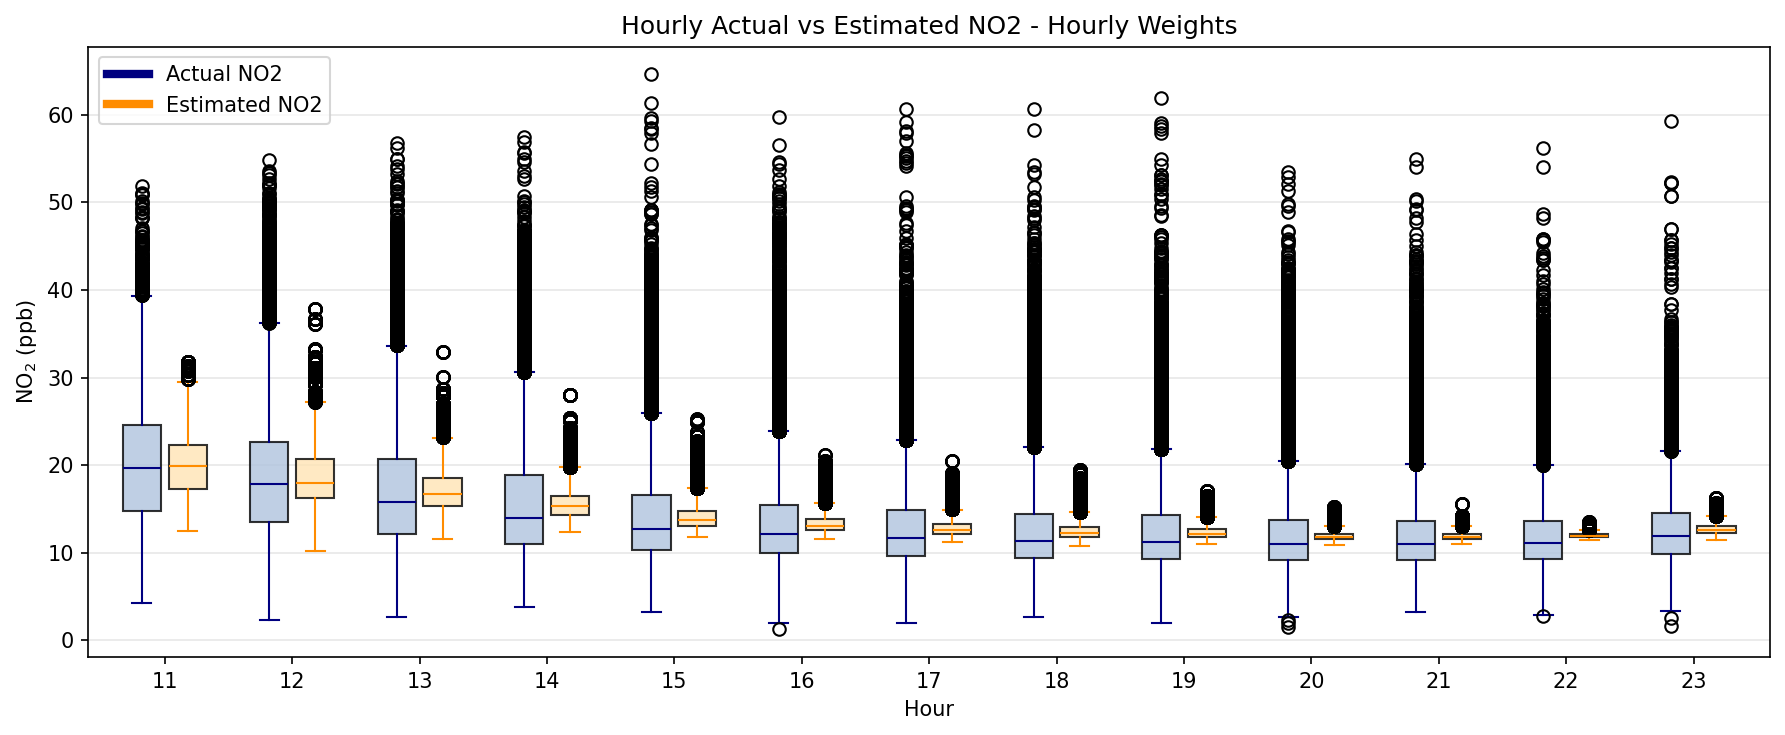

In [67]:


both = ct_full_dat[['hour','latitude','longitude','no2ConcIndividual.value','column_no2']].dropna()

model_rows = []
for hour in sorted(both['hour'].dropna().unique()):
    x_hour = both.loc[both['hour'] == hour, ['column_no2']]
    y_hour = both.loc[both['hour'] == hour, ['no2ConcIndividual.value']]

    if len(x_hour) < 2:
        continue

    hour_model = linear_model.LinearRegression().fit(X=x_hour, y=y_hour)
    model_rows.append({
        'hour': hour,
        'coef': float(hour_model.coef_.ravel()[0]),
        'intercept': float(hour_model.intercept_.ravel()[0]),
        'score': hour_model.score(X=x_hour, y=y_hour)
    })

model_vals = pd.DataFrame(model_rows)
print(model_vals)

both = both.merge(model_vals, on='hour', how='left')
both['no2_estimate'] = both['column_no2'] * both['coef'] + both['intercept']

hour_rmse = both.groupby('hour').apply(
    lambda group: rmse(group['no2ConcIndividual.value'], group['no2_estimate'])
)
both['rmse'] = both['hour'].map(hour_rmse)

print(both.head())

sns.kdeplot(both, x="no2ConcIndividual.value", color="blue", label='Actual Surface NO$_2$')
sns.kdeplot(both, x='no2_estimate', color="green", label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - Time of Day Aggregated - Hourly Weights")
plt.legend()
savefig("kde-actual-and-estimated-tod-hourly-weight-alldat.png")
plt.show()

hour_rmse_df = hour_rmse.reset_index()
hour_rmse_df.columns = ['hour', 'rmse']

plt.figure(figsize=(8, 4))
plt.plot(hour_rmse_df['hour'], hour_rmse_df['rmse'], marker='o', color='darkred')
plt.xticks(hour_rmse_df['hour'])
plt.xlabel('Hour')
plt.ylabel('RMSE')
plt.title('Model RMSE by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-rmse-alldat.png")
plt.show()


plt.figure(figsize=(8, 4))
plt.plot(model_vals['hour'], model_vals['score'], marker='o', color='darkblue')
plt.xticks(model_vals['hour'])
plt.xlabel('Hour')
plt.ylabel('R$^2$')
plt.title('Model R$^2$ by Hour - Hourly Weights')
plt.grid(True, alpha=0.3)
plt.tight_layout()
savefig("hourly-weights-r2-alldat.png")
plt.show()


hour_dat = both[['hour']].drop_duplicates().sort_values('hour').reset_index(drop=True)

hours = [int(hour) for hour in hour_dat['hour'].to_list()]
actual_by_hour = [both.loc[both['hour'] == hour, 'no2ConcIndividual.value'].dropna() for hour in hours]
estimated_by_hour = [both.loc[both['hour'] == hour, 'no2_estimate'].dropna() for hour in hours]

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [hour - 0.18 for hour in hours]
positions_estimated = [hour + 0.18 for hour in hours]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(hours)
ax.set_xticklabels(hours)
ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
ax.set_xlabel('Hour')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Hourly Actual vs Estimated NO2 - Hourly Weights')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()

savefig("boxplots-actual-vs-estimated-no2-hourly-weights-alldat.png")
plt.show()



# Random Plotting


#### Boxplot of Actual vs Estimated NO2

In [68]:
hour_dat = both[['hour']].drop_duplicates().sort_values('hour').reset_index(drop=True)

hours = [int(hour) for hour in hour_dat['hour'].to_list()]
actual_by_hour = [both.loc[both['hour'] == hour, 'sfc_no2_mean'].dropna() for hour in hours]
estimated_by_hour = [both.loc[both['hour'] == hour, 'no2_estimate'].dropna() for hour in hours]

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [hour - 0.18 for hour in hours]
positions_estimated = [hour + 0.18 for hour in hours]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(hours)
ax.set_xticklabels(hours)
ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
ax.set_xlabel('Hour')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Hourly Actual vs Estimated NO2 - Hourly Weights - Winter Filter')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()

savefig("boxplots-actual-vs-estimated-no2-hourly-weights-nowinter.png")
plt.show()

KeyError: 'sfc_no2_mean'

#### Boxplot of tempo values by hour

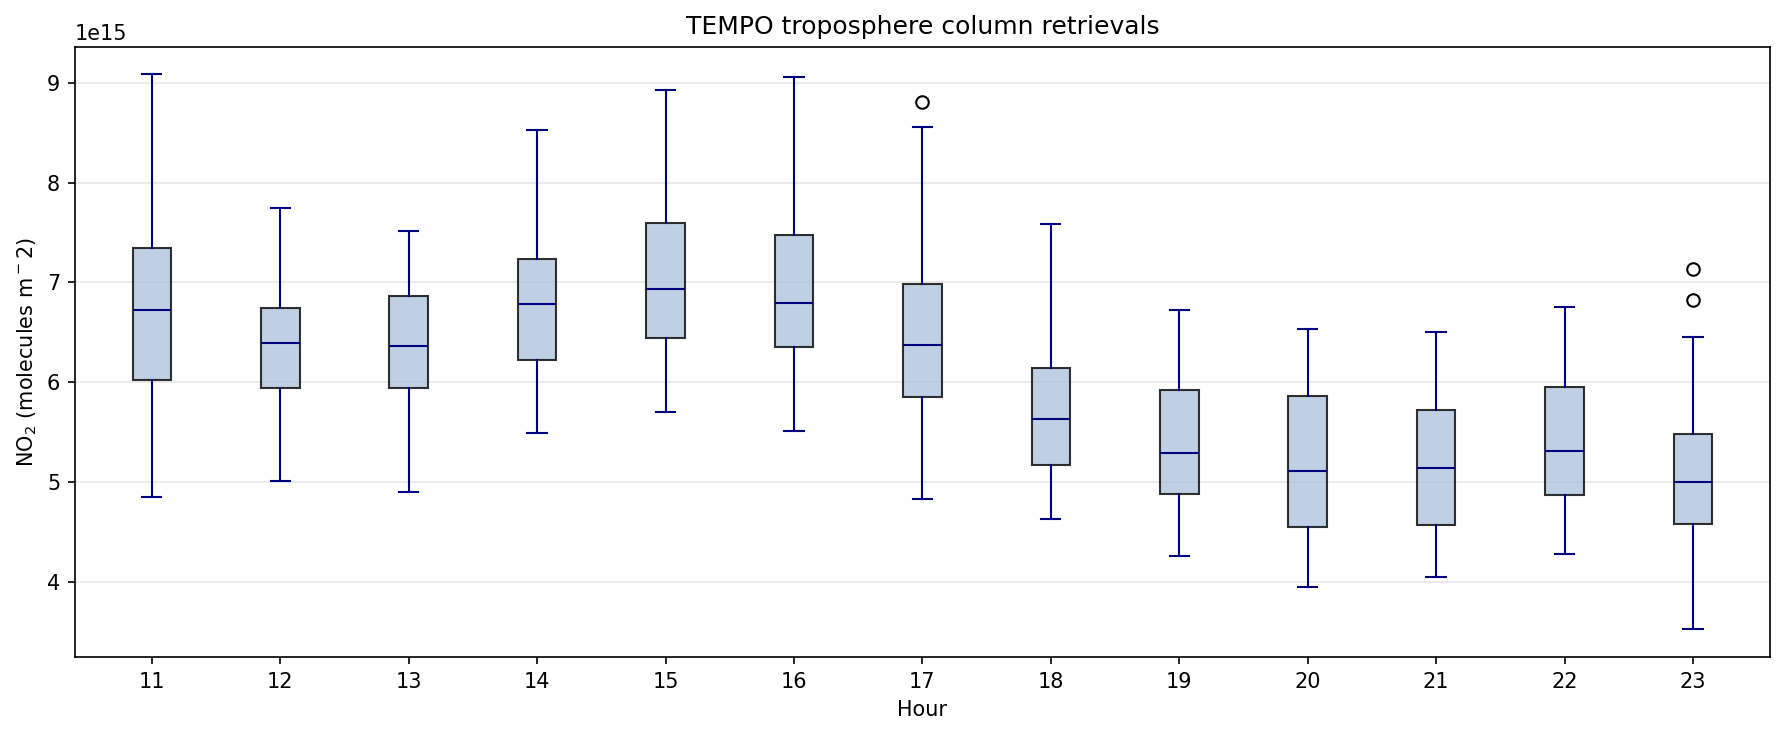

In [ ]:
# tempo_vals =  ct_diurnal.column_no2_mean.to_dataframe().reset_index()
# clarity_vals = ct_diurnal.sfc_no2_mean.to_dataframe().reset_index()

# both = clarity_vals.merge(tempo_vals, on=['latitude', 'longitude', 'hour']).dropna()


both = ct_nowinter[['hour','latitude','longitude','sfc_no2_mean','col_no2_mean']].dropna()

hour_dat = both[['hour']].drop_duplicates().sort_values('hour').reset_index(drop=True)
hours = [int(hour) for hour in hour_dat['hour'].to_list()]

fig, ax = plt.subplots(figsize=(12, 5))

# hours = [int(hour) for hour in tempo_vals['hour'].to_list()]
actual_by_hour = [both.loc[both['hour'] == hour, 'col_no2_mean'].dropna() for hour in hours]
positions_actual = [hour for hour in hours]


ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)

ax.set_xticks(hours)
ax.set_xticklabels(hours)
ax.set_xlim(min(hours) - 0.6, max(hours) + 0.6)
ax.set_xlabel('Hour')
ax.set_ylabel('NO$_2$ (molecules m$^-2$)')
ax.set_title('TEMPO troposphere column retrievals')
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()

savefig("boxplot-tempo-mean-vals.png")
plt.show()

In [ ]:

# Attach the hourly model results before computing the estimate and plotting
hour_lookup = model_vals.set_index('hour')
both['coef'] = both['hour'].map(hour_lookup['coef'])
both['intercept'] = both['hour'].map(hour_lookup['intercept'])
both['score'] = both['hour'].map(hour_lookup['score'])
both['no2_estimate'] = both['column_no2_mean'] * both['coef'] + both['intercept']
print(both.head())

# Build gridded rasters from the lat/lon cells in the notebook
score_grid = both.pivot_table(
    index='latitude',
    columns='longitude',
    values='score',
    aggfunc='mean',
).sort_index(axis=0).sort_index(axis=1)
estimate_grid = both.pivot_table(
    index='latitude',
    columns='longitude',
    values='no2_estimate',
    aggfunc='mean',
).sort_index(axis=0).sort_index(axis=1)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

hourly_scores = model_vals.sort_values('hour')
axes[0].plot(hourly_scores['hour'], hourly_scores['score'], marker='o', color='navy')
axes[0].set_title('Hourly Model Score')
axes[0].set_xlabel('Hour')
axes[0].set_ylabel('Score')
axes[0].grid(True, alpha=0.3)

estimate_image = axes[1].imshow(
    estimate_grid.to_numpy(),
    extent=[estimate_grid.columns.min(), estimate_grid.columns.max(), estimate_grid.index.min(), estimate_grid.index.max()],
    origin='lower',
    cmap='plasma',
    aspect='equal',
)
axes[1].set_title('Raster Plot of NO2 Estimate')
axes[1].set_xlabel('Longitude')
axes[1].set_ylabel('Latitude')
fig.colorbar(estimate_image, ax=axes[1], fraction=0.046, pad=0.04)

plt.show()

KeyError: 'column_no2_mean'